# 04 Integrate multi-omics data


In [1]:
import matplotlib.pyplot as plt
import msmu as mm
import mofax as mofa
import muon as mu
import scanpy as sc

random_state = 42

/Users/jl/Scripts/msmu/docs/tutorials/2024_Fulcher/.venv/lib/python3.13/site-packages/muon/_core/preproc.py:32: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  if Version(scanpy.__version__) < Version("1.10"):


## Combine modalities with matching cell IDs


In [2]:
adata = sc.read_h5ad("GSE201575.h5ad")
mdata = mm.read_h5mu("MSV000089280_imputed.h5mu")

mdata.mod["rna"] = adata
mdata.update()
mdata

MuData object with n_obs × n_vars = 70 × 98669
  obs:	'source name', 'characteristics[organism]', 'characteristics[organism part]', 'characteristics[disease]', 'characteristics[cell line]', 'characteristics[biological replicate]', 'assay name', 'technology type', 'comment[proteomics data acquisition method]', 'comment[label]', 'comment[instrument]', 'comment[cleavage agent details]', 'comment[modification parameters]', 'comment[modification parameters].1', 'comment[modification parameters].2', 'comment[fraction identifier]', 'comment[technical replicate]', 'comment[file uri]', 'factor value[sample]', 'factor value[condition]', 'factor value[rna data file]'
  uns:	'_log', 'sdrf'
  4 modalities
    psm:	70 × 80375
      obs:	'source name', 'characteristics[organism]', 'characteristics[organism part]', 'characteristics[disease]', 'characteristics[cell line]', 'characteristics[biological replicate]', 'assay name', 'technology type', 'comment[proteomics data acquisition method]', 'comment[l

## Build a WNN UMAP


In [3]:
mdata_subset = mu.MuData({"protein": mdata.mod["protein"].copy(), "rna": mdata.mod["rna"].copy()})
mdata_subset.mod["protein"].X = mdata_subset.mod["protein"].layers["imputed"]

sc.pp.pca(mdata_subset.mod["rna"])
sc.pp.pca(mdata_subset.mod["protein"])
sc.pp.neighbors(mdata_subset.mod["rna"], n_pcs=4)
sc.pp.neighbors(mdata_subset.mod["protein"], n_pcs=4)

# Calculate weighted nearest neighbors (WNN)
mu.pp.neighbors(mdata_subset, key_added="wnn")
mu.tl.umap(mdata_subset, neighbors_key="wnn", random_state=random_state)

mdata.obsm["WNN_UMAP"] = mdata_subset.obsm["X_umap"]

/Users/jl/Scripts/msmu/docs/tutorials/2024_Fulcher/.venv/lib/python3.13/site-packages/pynndescent/pynndescent_.py:1241: UserWarning: Failed to correctly find n_neighbors for some samples. Results may be less than ideal. Try re-running with different parameters.
  warn(
/Users/jl/Scripts/msmu/docs/tutorials/2024_Fulcher/.venv/lib/python3.13/site-packages/pynndescent/pynndescent_.py:1241: UserWarning: Failed to correctly find n_neighbors for some samples. Results may be less than ideal. Try re-running with different parameters.
  warn(


### Inspect the WNN embedding


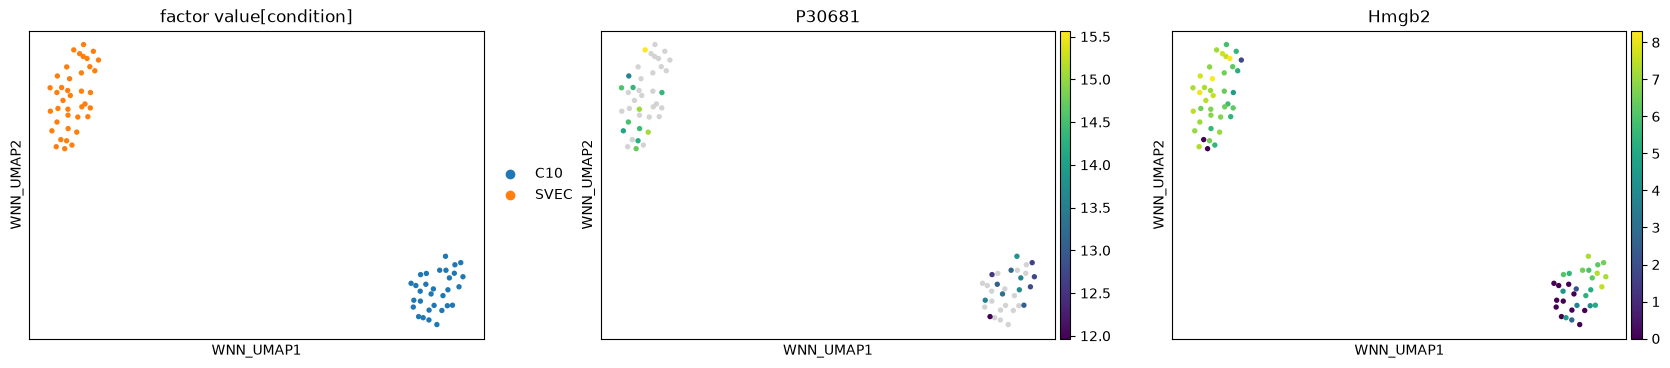

In [4]:
with plt.rc_context({"figure.figsize": (6, 4)}):
    mu.pl.embedding(
        mdata, basis="WNN_UMAP",
        color=["factor value[condition]", "P30681", "Hmgb2"], size=60,
    )

## Fit a MOFA model


In [5]:
mdata_subset = mu.MuData({"protein": mdata.mod["protein"].copy(), "rna": mdata.mod["rna"].copy()})

mdata_subset

MuData object with n_obs × n_vars = 70 × 14384
  2 modalities
    protein:	70 × 933
      obs:	'source name', 'characteristics[organism]', 'characteristics[organism part]', 'characteristics[disease]', 'characteristics[cell line]', 'characteristics[biological replicate]', 'assay name', 'technology type', 'comment[proteomics data acquisition method]', 'comment[label]', 'comment[instrument]', 'comment[cleavage agent details]', 'comment[modification parameters]', 'comment[modification parameters].1', 'comment[modification parameters].2', 'comment[fraction identifier]', 'comment[technical replicate]', 'comment[file uri]', 'factor value[sample]', 'factor value[condition]', 'factor value[rna data file]'
      var:	'count_psm', 'count_stripped_peptide', 'PEP', 'q_value', 'n_missing', 'missing_ratio'
      uns:	'decoy', 'decoy_filter', 'filter', 'level'
      varm:	'filter'
      layers:	'imputed', None
    rna:	70 × 13451
      obs:	'source name', 'characteristics[organism]', 'characteristics[

### Train the model


In [6]:
mu.tl.mofa(mdata_subset, outfile="MOFA_model.hdf5", seed=random_state)


        #########################################################
        ###           __  __  ____  ______                    ### 
        ###          |  \/  |/ __ \|  ____/\    _             ### 
        ###          | \  / | |  | | |__ /  \ _| |_           ### 
        ###          | |\/| | |  | |  __/ /\ \_   _|          ###
        ###          | |  | | |__| | | / ____ \|_|            ###
        ###          |_|  |_|\____/|_|/_/    \_\              ###
        ###                                                   ### 
        ######################################################### 
         


Loaded view='protein' group='group1' with N=70 samples and D=933 features...
Loaded view='rna' group='group1' with N=70 samples and D=13451 features...


Model options:
- Automatic Relevance Determination prior on the factors: True
- Automatic Relevance Determination prior on the weights: True
- Spike-and-slab prior on the factors: False
- Spike-and-slab prior on the weights: True
Like

### Inspect the saved model


MOFA+ model: MOFA model
Samples (cells): 70
Features: 14384
Groups: group1 (70)
Views: protein (933), rna (13451)
Factors: 10
Expectations: W, Z

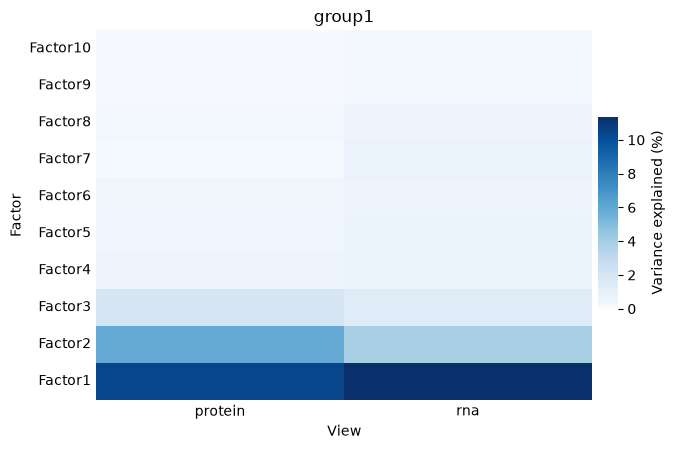

In [7]:
model = mofa.mofa_model("MOFA_model.hdf5")
display(model)
display(mofa.plot_r2(model, x="View", cbar_kws={"label": "Variance explained (%)"}))

protein_weights = model.get_weights(views="protein", factors=0, df=True).iloc[:, 0]
rna_weights = model.get_weights(views="rna", factors=0, df=True).iloc[:, 0]
model.close()

### Leading protein features of factor 1


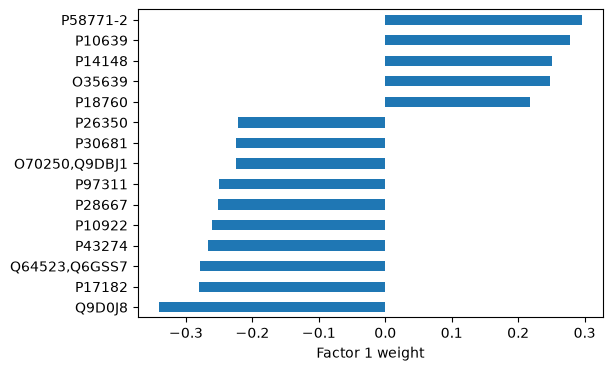

In [8]:
top_protein = protein_weights.loc[protein_weights.abs().nlargest(15).index]
top_protein.sort_values().plot.barh(figsize=(6, 4), xlabel="Factor 1 weight")
plt.show()

### Leading RNA features of factor 1


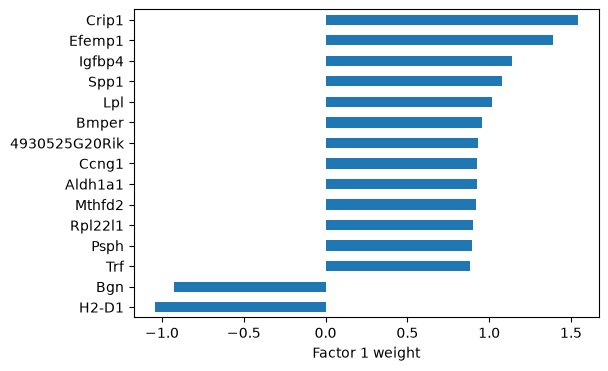

In [9]:
top_rna = rna_weights.loc[rna_weights.abs().nlargest(15).index]
top_rna.sort_values().plot.barh(figsize=(6, 4), xlabel="Factor 1 weight")
plt.show()

## Save the multimodal checkpoint


In [10]:
mdata.write_h5mu("Fulcher_multimodal.h5mu")